In [1]:
# Confere se as bibliotecas foram instaladas, mostrando a versão de cada uma.

import pandas as pd, sklearn, xgboost
print(pd.__version__, sklearn.__version__, xgboost.__version__)

3.1.1 1.9.1 3.4.1


In [2]:
# Lê o arquivo da base Bank Marketing. Nesse arquivo, o separador de colunas deve ser por ponto e vírgula (";").

df = pd.read_csv("data/bank-full.csv", sep=";")
print(df.shape)
df.head()

(45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
# Mostra um resumo das informações da tabela.

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [4]:
# Retorna o número de linhas duplicadas e de colunas com valores "unknown".
print("Duplicados:", df.duplicated().sum())

for col in df.select_dtypes(include="str").columns:
    n = (df[col] == "unknown").sum()
    if n > 0:
        print(col, n)

Duplicados: 0
job 288
education 1857
contact 13020
poutcome 36959


In [5]:
# Hipótese: o "unknown" em poutcome (resultado da campanha anterior) não é dado perdido, e sim "cliente nunca foi contatado antes"
# Hipótese confirmada.

pd.crosstab(df["poutcome"], df["previous"] == 0)

previous,False,True
poutcome,,
failure,4901,0
other,1840,0
success,1511,0
unknown,5,36954


In [6]:
# Conta quantos clientes aceitaram (yes) ou recusaram (no), em quantidade e proporção

print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True))

y
no     39922
yes     5289
Name: count, dtype: int64
y
no     0.883015
yes    0.116985
Name: proportion, dtype: float64


In [7]:
# Resumo estatístico das colunas numéricas (mínimo, máximo, média) para achar valores 'estranhos'


df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [8]:
# Conta casos suspeitos nas colunas numéricas (códigos como -1, zeros e extremos)

print("pdays == -1:", (df["pdays"] == -1).sum())
print("pdays == -1 e previous > 0:", ((df["pdays"] == -1) & (df["previous"] > 0)).sum())
print("duration == 0:", (df["duration"] == 0).sum())
print("balance < 0:", (df["balance"] < 0).sum())
print("previous > 50:", (df["previous"] > 50).sum())

pdays == -1: 36954
pdays == -1 e previous > 0: 0
duration == 0: 3
balance < 0: 3766
previous > 50: 4


In [9]:
dados = df.copy()
dados["previously_contacted"] = (dados["pdays"] != -1).astype(int)
dados["pdays"] = dados["pdays"].replace(-1,0)
dados = dados.drop(columns=["duration"])
y = (dados["y"] == "yes").astype(int)
X = dados.drop(columns=["y"])
print(X.shape, y.shape)

(45211, 16) (45211,)


In [10]:
# Separa os nomes das colunas numéricas e das colunas de texto

colunas_num = ["age", "balance", "day", "campaign", "pdays", "previous", "previously_contacted"]
colunas_cat = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]

In [11]:
# Monta o pré-processador (números na mesma escala, texto em colunas 0/1), sem treinar ainda

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessador = ColumnTransformer([
    ("num", StandardScaler(), colunas_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), colunas_cat),
])

In [12]:
# Só para conferir quantas colunas o X terá depois da transformação

print(preprocessador.fit_transform(X).shape)

(45211, 51)


In [13]:
# Cria as 5 partições estratificadas com semente fixa (pois o grupo usa essa mesma)

from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [14]:
# Confere o tamanho e a proporção de "yes" no teste de cada partição

for i, (idx_treino, idx_teste) in enumerate(skf.split(X, y), start=1):
    print(f"Partição {i}: treino={len(idx_treino)}, teste={len(idx_teste)}, yes no teste={y.iloc[idx_teste].mean():.3f}")

Partição 1: treino=36168, teste=9043, yes no teste=0.117
Partição 2: treino=36169, teste=9042, yes no teste=0.117
Partição 3: treino=36169, teste=9042, yes no teste=0.117
Partição 4: treino=36169, teste=9042, yes no teste=0.117
Partição 5: treino=36169, teste=9042, yes no teste=0.117


In [15]:
# Teste de ponta a ponta com um KNN simples nas 5 partições (só valida a estrutura, não são resultados finais)

from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

teste = Pipeline([("prep", preprocessador), ("modelo", KNeighborsClassifier())])
print(cross_val_score(teste, X, y, cv=skf, scoring="f1"))

[0.30183549 0.32053872 0.31078366 0.28746594 0.32671958]


## Avaliação dos classificadores (métricas e matriz de confusão)

Função comum para todos os modelos. Use assim:

```python
avaliar("KNN", "k=5", KNeighborsClassifier(n_neighbors=5))
```

- Treina o pipeline (pré-processador + modelo) nas **mesmas 5 partições** do `skf`; o pré-processador é ajustado só com o treino de cada rodada.
- Calcula acurácia, precisão, revocação e F1 da classe positiva (`yes` = 1) em cada partição e reporta **média ± desvio-padrão** das 5.
- Soma as matrizes de confusão das 5 partições (cada registro cai no teste exatamente uma vez, então a matriz cobre os 45.211 registros).
- Salva o resultado em `resultados/<modelo>__<config>.json`, para juntar os resultados de todos sem rodar tudo de novo. Rodar de novo a mesma configuração sobrescreve o arquivo.
- Critério para escolher a melhor configuração de cada modelo: **maior F1 médio da classe "sim"**.

In [26]:
import json, re, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

PASTA_RESULTADOS = Path("resultados")
PASTA_FIGURAS = Path("figuras")
PASTA_RESULTADOS.mkdir(exist_ok=True)
PASTA_FIGURAS.mkdir(exist_ok=True)

METRICAS = {"acuracia": "Acurácia", "precisao": "Precisão", "revocacao": "Revocação", "f1": "F1-score"}


def _rodar_particao(pipe, X, y, idx_treino, idx_teste):
    """Treina em uma partição e devolve as métricas e a matriz de confusão do teste."""
    modelo = clone(pipe).fit(X.iloc[idx_treino], y.iloc[idx_treino])
    y_true = y.iloc[idx_teste]
    y_pred = modelo.predict(X.iloc[idx_teste])
    return {
        "acuracia": accuracy_score(y_true, y_pred),
        "precisao": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "revocacao": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "matriz": confusion_matrix(y_true, y_pred, labels=[0, 1]),
    }


def _nome_arquivo(modelo, config):
    return PASTA_RESULTADOS / (re.sub(r"[^\w=.,-]+", "_", f"{modelo}__{config}") + ".json")


def avaliar(modelo, config, estimador, n_jobs=1, X=X, y=y, cv=skf):
    """Avalia um classificador nas 5 partições fixas e salva o resultado.

    modelo:    nome do algoritmo ("KNN", "SVM", "Random Forest", "XGBoost")
    config:    descrição curta dos hiperparâmetros (ex.: "k=15, weights=distance")
    estimador: o classificador do scikit-learn/XGBoost, ainda não treinado
    n_jobs:    partições rodadas em paralelo (útil para KNN e SVM; deixe 1 em RF/XGBoost,
               que já usam vários núcleos internamente)

    O resultado fica salvo em resultados/; veja com tabela_resultados().
    """
    pipe = Pipeline([("prep", preprocessador), ("modelo", estimador)])
    inicio = time.time()
    por_particao = Parallel(n_jobs=n_jobs)(
        delayed(_rodar_particao)(pipe, X, y, tr, te) for tr, te in cv.split(X, y)
    )
    resultado = {"modelo": modelo, "config": config, "parametros": str(estimador.get_params()),
                 "tempo_s": round(time.time() - inicio, 1)}
    for m in METRICAS:
        valores = [p[m] for p in por_particao]
        resultado[m] = valores
        resultado[m + "_media"] = float(np.mean(valores))
        resultado[m + "_dp"] = float(np.std(valores, ddof=1))
    resultado["matriz"] = sum(p["matriz"] for p in por_particao).tolist()

    with open(_nome_arquivo(modelo, config), "w", encoding="utf-8") as f:
        json.dump(resultado, f, ensure_ascii=False, indent=2)

    print(f"{modelo} [{config}] em {resultado['tempo_s']}s -> " + ", ".join(
        f"{rotulo} {resultado[m + '_media']:.3f} ± {resultado[m + '_dp']:.3f}" for m, rotulo in METRICAS.items()))


In [27]:
def carregar_resultados():
    """Lê todos os resultados salvos em resultados/ (de qualquer integrante)."""
    return [json.load(open(a, encoding="utf-8")) for a in sorted(PASTA_RESULTADOS.glob("*.json"))]


def tabela_resultados(apenas_melhores=False):
    """Tabela com média ± desvio-padrão das 5 partições, ordenada por F1.
    apenas_melhores=True mantém só a melhor configuração (maior F1) de cada modelo."""
    linhas = []
    for r in carregar_resultados():
        linha = {"Modelo": r["modelo"], "Configuração": r["config"], "_f1": r["f1_media"]}
        for m, rotulo in METRICAS.items():
            linha[rotulo] = f"{r[m + '_media']:.3f} ± {r[m + '_dp']:.3f}"
        linha["Tempo (s)"] = r["tempo_s"]
        linhas.append(linha)
    tabela = pd.DataFrame(linhas).sort_values("_f1", ascending=False)
    if apenas_melhores:
        tabela = tabela.drop_duplicates("Modelo")
    return tabela.drop(columns="_f1").reset_index(drop=True)


def melhores_por_modelo():
    """Resultado da melhor configuração (maior F1 médio) de cada modelo."""
    melhores = {}
    for r in carregar_resultados():
        if r["modelo"] not in melhores or r["f1_media"] > melhores[r["modelo"]]["f1_media"]:
            melhores[r["modelo"]] = r
    return sorted(melhores.values(), key=lambda r: -r["f1_media"])

In [28]:
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
from matplotlib.ticker import FuncFormatter

virgula = lambda v, casas=2: f"{v:.{casas}f}".replace(".", ",")
CORES_METRICAS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # ordem fixa: acurácia, precisão, revocação, F1


def plotar_matriz_confusao(resultado, ax=None, titulo=None):
    """Matriz de confusão somada das 5 partições, com contagem e % da linha (classe real).
    titulo: texto do título (padrão: "modelo (configuração)")."""
    matriz = np.array(resultado["matriz"])
    percentual = matriz / matriz.sum(axis=1, keepdims=True)
    if ax is None:
        _, ax = plt.subplots(figsize=(3.2, 2.8))
    ax.imshow(percentual, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{matriz[i, j]:,}".replace(",", ".") + f"\n({percentual[i, j]:.1%})".replace(".", ","),
                    ha="center", va="center", color="white" if percentual[i, j] > 0.5 else "#0b0b0b")
    ax.set_xticks([0, 1], ["Não", "Sim"])
    ax.set_yticks([0, 1], ["Não", "Sim"])
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
    ax.set_title(titulo or f"{resultado['modelo']} ({resultado['config']})", fontsize=plt.rcParams["font.size"])
    for lado in ax.spines.values():
        lado.set_visible(False)
    return ax


def plotar_matrizes_melhores(salvar="matrizes_confusao.png", tamanho_painel=(3.2, 2.8), titulos_curtos=False):
    """Matrizes de confusão da melhor configuração de cada modelo, lado a lado (sem a linha de base).
    tamanho_painel: (largura, altura) de cada matriz, em polegadas.
    titulos_curtos: True mostra só o nome do modelo (a configuração vai na legenda da figura)."""
    melhores = [r for r in melhores_por_modelo() if r["modelo"] != "Linha de base"]
    if not melhores:
        print("Ainda não há resultados de modelos em resultados/.")
        return None
    colunas = 2 if len(melhores) > 1 else 1
    linhas = int(np.ceil(len(melhores) / colunas))
    fig, eixos = plt.subplots(linhas, colunas, figsize=(tamanho_painel[0] * colunas, tamanho_painel[1] * linhas),
                             squeeze=False)
    for r, ax in zip(melhores, eixos.flat):
        plotar_matriz_confusao(r, ax, titulo=r["modelo"] if titulos_curtos else None)
    for ax in list(eixos.flat)[len(melhores):]:
        ax.set_visible(False)
    fig.tight_layout()
    if salvar:
        fig.savefig(PASTA_FIGURAS / salvar, dpi=300, bbox_inches="tight")
    return fig


def plotar_comparacao(salvar="comparacao_modelos.png", figsize=(7, 3), rotulos=True):
    """Barras agrupadas: as 4 métricas (média ± dp) da melhor configuração de cada modelo.
    rotulos=False omite o valor sobre cada barra (útil em figuras pequenas)."""
    melhores = melhores_por_modelo()
    nomes = [r["modelo"] if figsize[0] >= 5 else r["modelo"].replace(" ", "\n", 1) for r in melhores]
    x = np.arange(len(nomes))
    largura = 0.2
    fig, ax = plt.subplots(figsize=figsize)
    for k, ((m, rotulo), cor) in enumerate(zip(METRICAS.items(), CORES_METRICAS)):
        medias = [r[m + "_media"] for r in melhores]
        dps = [r[m + "_dp"] for r in melhores]
        barras = ax.bar(x + (k - 1.5) * largura, medias, largura * 0.9, yerr=dps, capsize=2,
                        color=cor, label=rotulo, error_kw={"elinewidth": 0.8, "ecolor": "#52514e"})
        if rotulos:
            ax.bar_label(barras, labels=[virgula(v) for v in medias], fontsize=7, padding=2, color="#52514e")
    ax.set_xticks(x, nomes)
    ax.set_ylim(0, 1.05)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: virgula(v, 1)))
    ax.set_ylabel("Média nas 5 partições")
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.legend(ncol=4, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0),
              handlelength=1.2, columnspacing=1.0)
    fig.tight_layout()
    if salvar:
        fig.savefig(PASTA_FIGURAS / salvar, dpi=300, bbox_inches="tight")
    return fig

### Linha de base (referência)

Classificador que sempre prevê a classe majoritária ("não"). Serve para mostrar que a acurácia sozinha engana numa base desbalanceada: ~88% de acurácia com revocação zero. Também valida a função de avaliação.

In [29]:
from sklearn.dummy import DummyClassifier

avaliar("Linha de base", "sempre 'não'", DummyClassifier(strategy="most_frequent"))

Linha de base [sempre 'não'] em 0.8s -> Acurácia 0.883 ± 0.000, Precisão 0.000 ± 0.000, Revocação 0.000 ± 0.000, F1-score 0.000 ± 0.000


## Experimentos

Cada integrante adiciona aqui as células dos seus modelos, chamando `avaliar(...)` para cada configuração (pelo menos 2 por modelo).

### KNN e SVM (Myllena)

In [30]:
from sklearn.neighbors import KNeighborsClassifier

avaliar("KNN", "k=5, euclidiana", KNeighborsClassifier(n_neighbors=5), n_jobs=5) # KNN com k=5 e métrica padrão (Euclidiana)
avaliar("KNN", "k=15, manhattan", KNeighborsClassifier(n_neighbors=15, metric="manhattan"), n_jobs=5) # KNN com k=15 e métrica Manhattan

KNN [k=5, euclidiana] em 5.8s -> Acurácia 0.887 ± 0.002, Precisão 0.537 ± 0.015, Revocação 0.217 ± 0.013, F1-score 0.309 ± 0.016
KNN [k=15, manhattan] em 20.0s -> Acurácia 0.893 ± 0.002, Precisão 0.639 ± 0.020, Revocação 0.186 ± 0.015, F1-score 0.288 ± 0.020


In [34]:
from sklearn.svm import SVC

avaliar("SVM", "linear, C=1", SVC(kernel="linear", C=1), n_jobs=5) # SVM com Kernel Linear e C=1
avaliar("SVM", "rbf, C=5, balanced", SVC(kernel="rbf", C=5, class_weight="balanced"), n_jobs=5) # SVM com Kernel RBF, C=5 e class_weight='balanced'

SVM [linear, C=1] em 73.7s -> Acurácia 0.893 ± 0.002, Precisão 0.646 ± 0.026, Revocação 0.185 ± 0.017, F1-score 0.287 ± 0.023
SVM [rbf, C=5, balanced] em 276.9s -> Acurácia 0.823 ± 0.005, Precisão 0.347 ± 0.009, Revocação 0.576 ± 0.021, F1-score 0.433 ± 0.011


### Random Forest e XGBoost (Laís)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Random Forest: compara o modelo sem pesos com pesos balanceados por amostra.
avaliar(
    "Random Forest", "300 arvores, sem pesos",
    RandomForestClassifier(
        n_estimators=300, class_weight=None, random_state=42, n_jobs=-1
    )
)

avaliar(
    "Random Forest", "300 arvores, balanced_subsample",
    RandomForestClassifier(
        n_estimators=300, class_weight="balanced_subsample", random_state=42, n_jobs=-1
    )
)

# XGBoost: mesmos hiperparametros; varia apenas o peso da classe positiva.
parametros_xgb = dict(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
    random_state=42, n_jobs=-1
)

avaliar(
    "XGBoost", "300 arvores, scale_pos_weight=1",
    XGBClassifier(**parametros_xgb, scale_pos_weight=1)
)

avaliar(
    "XGBoost", "300 arvores, scale_pos_weight=7.55",
    XGBClassifier(**parametros_xgb, scale_pos_weight=7.55)
)


## Resultados consolidados

Reúne tudo que está em `resultados/`. As figuras vão para `figuras/` (300 dpi, para o artigo).

In [45]:
# Todas as configurações, ordenadas por F1
tabela_resultados()

,Modelo,Configuração,Acurácia,Precisão,Revocação,F1-score,Tempo (s)
0,XGBoost,"300 arvores, scale_pos_weight=7.55",0.817 ± 0.004,0.347 ± 0.007,0.635 ± 0.028,0.448 ± 0.011,6.8
1,SVM,"rbf, C=5, balanced",0.823 ± 0.005,0.347 ± 0.009,0.576 ± 0.021,0.433 ± 0.011,276.9
2,XGBoost,"300 arvores, scale_pos_weight=1",0.895 ± 0.002,0.646 ± 0.022,0.234 ± 0.016,0.343 ± 0.020,7.0
3,Random Forest,"300 arvores, sem pesos",0.893 ± 0.002,0.614 ± 0.023,0.236 ± 0.019,0.341 ± 0.023,15.2
4,Random Forest,"300 arvores, balanced_subsample",0.894 ± 0.002,0.631 ± 0.016,0.217 ± 0.015,0.323 ± 0.019,16.1
5,KNN,"k=5, euclidiana",0.887 ± 0.002,0.537 ± 0.015,0.217 ± 0.013,0.309 ± 0.016,5.8
6,KNN,"k=15, manhattan",0.893 ± 0.002,0.639 ± 0.020,0.186 ± 0.015,0.288 ± 0.020,20.0
7,SVM,"linear, C=1",0.893 ± 0.002,0.646 ± 0.026,0.185 ± 0.017,0.287 ± 0.023,73.7
8,Linha de base,sempre 'não',0.883 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.8


In [46]:
# Melhor configuração de cada modelo (critério: maior F1 médio da classe "sim")
tabela_resultados(apenas_melhores=True)

,Modelo,Configuração,Acurácia,Precisão,Revocação,F1-score,Tempo (s)
0,XGBoost,"300 arvores, scale_pos_weight=7.55",0.817 ± 0.004,0.347 ± 0.007,0.635 ± 0.028,0.448 ± 0.011,6.8
1,SVM,"rbf, C=5, balanced",0.823 ± 0.005,0.347 ± 0.009,0.576 ± 0.021,0.433 ± 0.011,276.9
2,Random Forest,"300 arvores, sem pesos",0.893 ± 0.002,0.614 ± 0.023,0.236 ± 0.019,0.341 ± 0.023,15.2
3,KNN,"k=5, euclidiana",0.887 ± 0.002,0.537 ± 0.015,0.217 ± 0.013,0.309 ± 0.016,5.8
4,Linha de base,sempre 'não',0.883 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.8


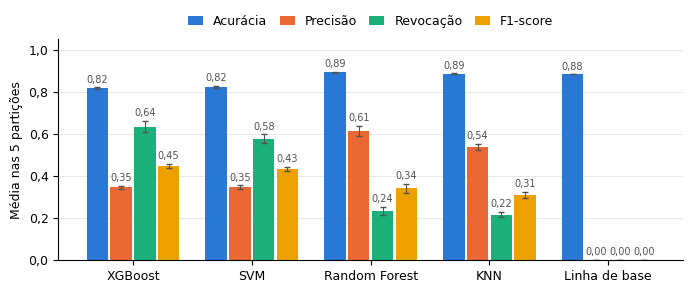

In [47]:
plotar_comparacao();

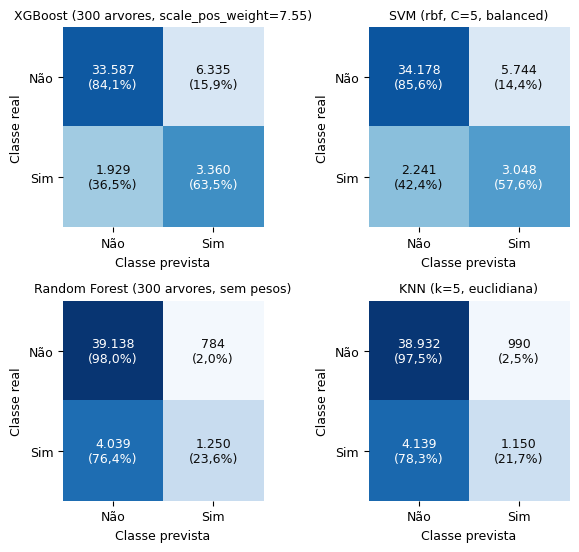

In [48]:
plotar_matrizes_melhores();

### Figuras para o artigo

Mesmos gráficos, no tamanho de uma coluna do modelo IEEE (3,5 pol.) e com fonte de 7 pt, para não ficarem ilegíveis quando reduzidos no PDF. Os arquivos `*_artigo.png` são os inseridos no artigo.

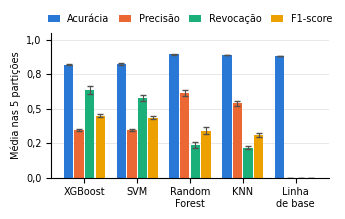

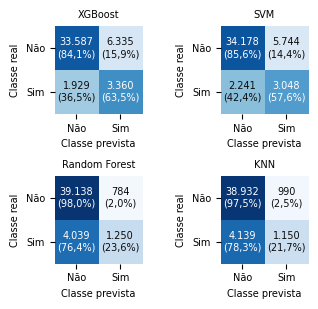

In [49]:
with plt.rc_context({"font.size": 7}):
    plotar_comparacao("comparacao_modelos_artigo.png", figsize=(3.5, 2.2), rotulos=False)
    plotar_matrizes_melhores("matrizes_confusao_artigo.png", tamanho_painel=(1.75, 1.55), titulos_curtos=True)